# Predicting Restaurant Quality from Zomato Data
### A Machine Learning approach to help diners choose better and help restaurants understand what drives customer satisfaction

**Course project (CA2) | Domain: Data-driven prediction for a societal challenge**

---
## 1. Problem Statement

**Societal challenge.** Every day millions of people decide where to eat using online ratings. But a new or small restaurant has few or no reviews, so diners cannot judge it, and owners (often small businesses) do not know which factors drive good ratings. Ratings of unrated places are also unavailable exactly when they matter most (when a restaurant opens).

**Data-driven question.** *Can we predict the quality class of a restaurant (Low / Good / High) from its observable characteristics: price, services offered, cuisines, location and, when available, customer engagement (votes)?*

### Measurable Objectives

| # | Objective | Success criterion |
|---|-----------|-------------------|
| O1 | Prepare and clean the data (missing values, invalid costs, currency normalisation, unrated records) | 0 missing values and 0 duplicates in the modelling table |
| O2 | Explore patterns with EDA and statistical tests | at least 10 visualisations and at least 5 hypothesis tests with effect sizes |
| O3 | **Scenario A** (restaurant already has votes): classify the quality class | Macro-F1 >= 0.70 and Accuracy >= 0.70 on the unseen test set |
| O4 | **Scenario B** (new restaurant, no votes): classify the quality class from static features only | Macro-F1 >= 0.58 (random guessing gives about 0.33) |
| O5 | Predict the exact rating (regression) | Scenario A: RMSE <= 0.40 and R2 >= 0.50 |
| O6 | Identify the key drivers of ratings | Permutation importance computed on held-out data |
| O7 | Apply the model to unrated restaurants | Predicted quality class for every "Not rated" restaurant |

**Dataset.** Zomato Restaurants dataset (9,551 restaurants, 15 countries, 21 columns), publicly available on Kaggle ("Zomato Restaurants Data").

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, json, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='deep', font_scale=1.0)
plt.rcParams['figure.dpi'] = 100
os.makedirs('figures', exist_ok=True); os.makedirs('outputs', exist_ok=True); os.makedirs('models', exist_ok=True)
RANDOM_STATE = 42
FIG = 0
def savefig(name):
    global FIG; FIG += 1
    plt.tight_layout(); plt.savefig(f'figures/{FIG:02d}_{name}.png', dpi=150, bbox_inches='tight'); plt.show()

## 2. Data Understanding

In [2]:
raw = pd.read_csv('data/Zomato Restaurant Dataset.csv', encoding='utf-8', encoding_errors='replace')
print('Shape:', raw.shape)
raw.head()

Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
info = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'unique': raw.nunique()})
display(info)
print('Duplicate Restaurant IDs:', raw['Restaurant ID'].duplicated().sum())
print('Fully duplicated rows   :', raw.duplicated().sum())

,dtype,missing,unique
Restaurant ID,int64,0,9551
Restaurant Name,str,0,7446
Country Code,int64,0,15
City,str,0,141
Address,str,0,8918
Locality,str,0,1208
Locality Verbose,str,0,1265
Longitude,float64,0,8120
Latitude,float64,0,8677
Cuisines,str,9,1825


Duplicate Restaurant IDs: 0
Fully duplicated rows   : 0


In [4]:
display(raw[['Average Cost for two','Price range','Aggregate rating','Votes']].describe().T)
print(raw['Rating text'].value_counts())
print(raw.groupby('Rating text')['Aggregate rating'].agg(['min','max']))

,count,mean,std,min,25%,50%,75%,max
Average Cost for two,9551.0,1199.210763,16121.183073,0.0,250.0,400.0,700.0,800000.0
Price range,9551.0,1.804837,0.905609,1.0,1.0,2.0,2.0,4.0
Aggregate rating,9551.0,2.666370,1.516378,0.0,2.5,3.2,3.7,4.9
Votes,9551.0,156.909748,430.169145,0.0,5.0,31.0,131.0,10934.0


Rating text
Average      3737
Not rated    2148
Good         2100
Very Good    1079
Excellent     301
Poor          186
Name: count, dtype: int64
             min  max
Rating text          
Average      2.5  3.4
Excellent    4.5  4.9
Good         3.5  3.9
Not rated    0.0  0.0
Poor         1.8  2.4
Very Good    4.0  4.4


**Observations**
* Only `Cuisines` has missing values (9 rows).
* `Switch to order menu` has a single value ("No") for every row, so it carries no information.
* **2,148 restaurants have rating 0 ("Not rated")**. This is not a real rating, it means *no rating exists*. They must not be used as training labels, but they are the exact population our model will be applied to later.
* `Average Cost for two` is stored in **12 different currencies**, so it cannot be compared across countries without normalisation.
* `Rating text` and `Rating color` are directly derived from the target rating (data leakage risk), so they are excluded from features.

## 3. Data Preparation and Cleaning

In [5]:
df = raw.copy()

# 3.1 Drop constant / identifier-like / leakage columns later; first fix basic issues
df['Cuisines'] = df['Cuisines'].fillna('Unknown')

# 3.2 Country names from the Zomato country-code list
country_map = {1:'India',14:'Australia',30:'Brazil',37:'Canada',94:'Indonesia',148:'New Zealand',162:'Philippines',
               166:'Qatar',184:'Singapore',189:'South Africa',191:'Sri Lanka',208:'Turkey',214:'UAE',215:'United Kingdom',216:'United States'}
df['Country'] = df['Country Code'].map(country_map)
print('Unmapped countries:', df['Country'].isna().sum())

# 3.3 Currency issue: Philippines rows are labelled 'Botswana Pula' in the source file; values are Philippine Pesos.
print(df.groupby('Country')['Currency'].agg(lambda s: s.mode()[0]).to_frame().T.T)

Unmapped countries: 0
                              Currency
Country                               
Australia                    Dollar($)
Brazil              Brazilian Real(R$)
Canada                       Dollar($)
India               Indian Rupees(Rs.)
Indonesia       Indonesian Rupiah(IDR)
New Zealand              NewZealand($)
Philippines           Botswana Pula(P)
Qatar                  Qatari Rial(QR)
Singapore                    Dollar($)
South Africa                   Rand(R)
Sri Lanka        Sri Lankan Rupee(LKR)
Turkey                Turkish Lira(TL)
UAE                 Emirati Diram(AED)
United Kingdom              Pounds(��)
United States                Dollar($)


In [6]:
# 3.4 Approximate conversion to USD (mid-2018 era rates, the period this dataset was scraped).
# Used only to compare cost levels across countries; the model also uses a currency-free relative cost feature.
usd_rate = {'India':0.0147,'Australia':0.74,'Brazil':0.27,'Canada':0.77,'Indonesia':0.00007,'New Zealand':0.68,'Philippines':0.019,
            'Qatar':0.275,'Singapore':0.74,'South Africa':0.075,'Sri Lanka':0.0065,'Turkey':0.25,'UAE':0.272,'United Kingdom':1.33,'United States':1.0}
df['cost_usd'] = df['Average Cost for two'] * df['Country'].map(usd_rate)

# 3.5 Invalid cost (0) -> treat as missing and impute by the median of (country, price range)
zero_cost = (df['Average Cost for two'] == 0).sum()
df['Average Cost for two'] = df['Average Cost for two'].replace(0, np.nan)
grp_med = df.groupby(['Country','Price range'])['Average Cost for two'].transform('median')
df['Average Cost for two'] = df['Average Cost for two'].fillna(grp_med)
df['Average Cost for two'] = df['Average Cost for two'].fillna(df.groupby('Country')['Average Cost for two'].transform('median'))
df['cost_usd'] = df['Average Cost for two'] * df['Country'].map(usd_rate)
print('Zero-cost rows imputed:', zero_cost, '| remaining missing cost:', df['Average Cost for two'].isna().sum())

# 3.6 Binary Yes/No -> 1/0
for c in ['Has Table booking','Has Online delivery','Is delivering now']:
    df[c] = (df[c] == 'Yes').astype(int)
df = df.drop(columns=['Switch to order menu'])   # constant column

Zero-cost rows imputed: 18 | remaining missing cost: 0


In [7]:
# 3.7 Outliers in cost: inspect with the IQR rule on the *relative* cost (cost / country median)
df['cost_rel'] = df['Average Cost for two'] / df.groupby('Country')['Average Cost for two'].transform('median')
q1, q3 = df['cost_rel'].quantile([.25,.75]); iqr = q3-q1
upper = q3 + 3*iqr
print(f'Extreme cost_rel outliers (> {upper:.2f}x country median):', (df['cost_rel']>upper).sum())
df['cost_rel'] = df['cost_rel'].clip(upper=df['cost_rel'].quantile(0.99))          # winsorise at 99th percentile
df['cost_usd_log'] = np.log1p(df['cost_usd'])
df['log_votes'] = np.log1p(df['Votes'])

Extreme cost_rel outliers (> 4.22x country median): 337


### 3.8 Handling the "Not rated" restaurants
Restaurants with rating 0 are **separated** from the modelling data (they have no label) and kept for the final prediction step.

In [8]:
unrated = df[df['Aggregate rating'] == 0].copy()
rated   = df[df['Aggregate rating'] > 0].copy()
print('Rated:', len(rated), '| Unrated:', len(unrated))
print('Votes for unrated restaurants -> mean: %.2f, share with 0 votes: %.1f%%' % (unrated['Votes'].mean(), 100*(unrated['Votes']==0).mean()))

Rated: 7403 | Unrated: 2148
Votes for unrated restaurants -> mean: 0.87, share with 0 votes: 50.9%


Unrated restaurants have (almost) no votes. This is why we build **two scenarios**: 
* **Scenario A** uses votes (restaurant already has customer engagement).
* **Scenario B** does *not* use votes, so it can be applied to new/unrated restaurants.

### 3.9 Feature engineering and target definition
* **Target (`quality_class`)** from the aggregate rating: `Low` (< 3.5), `Good` (3.5 to 3.9), `High` (>= 4.0). This keeps the classes meaningful and reasonably balanced.
* `n_cuisines`: number of cuisines offered
* Multi-hot flags for the 20 most common cuisines
* `chain_size`: how many outlets share the same restaurant name (chain indicator)
* `locality_density`: number of restaurants in the same locality (competition / footfall proxy)
* `cost_rel`: cost relative to the country median (currency-free)
* `city_grp`: top-15 cities, the rest as "Other"

In [9]:
def build_features(d):
    d = d.copy()
    d['n_cuisines'] = d['Cuisines'].apply(lambda s: 0 if s=='Unknown' else len([x for x in s.split(',') if x.strip()]))
    return d

rated = build_features(rated); unrated = build_features(unrated)
all_df = pd.concat([rated, unrated])

# Top cuisines (from rated data only)
cuis_counts = rated['Cuisines'].str.split(',').explode().str.strip().value_counts()
TOP_CUIS = cuis_counts.head(20).index.tolist()
print('Top 20 cuisines:', TOP_CUIS)

# chain size and locality density computed on the full dataset (no target involved)
chain = all_df['Restaurant Name'].value_counts(); loc = all_df['Locality Verbose'].value_counts()
TOP_CITIES = rated['City'].value_counts().head(15).index.tolist()

def finalize(d):
    d = d.copy()
    for c in TOP_CUIS:
        d['cu_'+c.replace(' ','_')] = d['Cuisines'].apply(lambda s, c=c: int(c in [x.strip() for x in s.split(',')]))
    d['chain_size'] = np.log1p(d['Restaurant Name'].map(chain))
    d['locality_density'] = np.log1p(d['Locality Verbose'].map(loc))
    d['city_grp'] = d['City'].where(d['City'].isin(TOP_CITIES), 'Other')
    return d
rated = finalize(rated); unrated = finalize(unrated)
rated['quality_class'] = pd.cut(rated['Aggregate rating'], [0, 3.45, 3.95, 5.0], labels=['Low','Good','High'])
rated['y'] = rated['quality_class'].map({'Low':0,'Good':1,'High':2}).astype(int)
print(rated['quality_class'].value_counts())
print('Missing values in modelling table:', rated.drop(columns=[]).isna().sum().sum(), '| Duplicate IDs:', rated['Restaurant ID'].duplicated().sum())
rated.to_csv('outputs/cleaned_rated_restaurants.csv', index=False)

Top 20 cuisines: ['North Indian', 'Chinese', 'Fast Food', 'Mughlai', 'Italian', 'Continental', 'Cafe', 'Desserts', 'Bakery', 'South Indian', 'Street Food', 'American', 'Pizza', 'Mithai', 'Burger', 'Thai', 'Asian', 'Beverages', 'Mexican', 'Seafood']


quality_class
Low     3923
Good    2100
High    1380
Name: count, dtype: int64
Missing values in modelling table: 0 | Duplicate IDs: 0


## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of the target

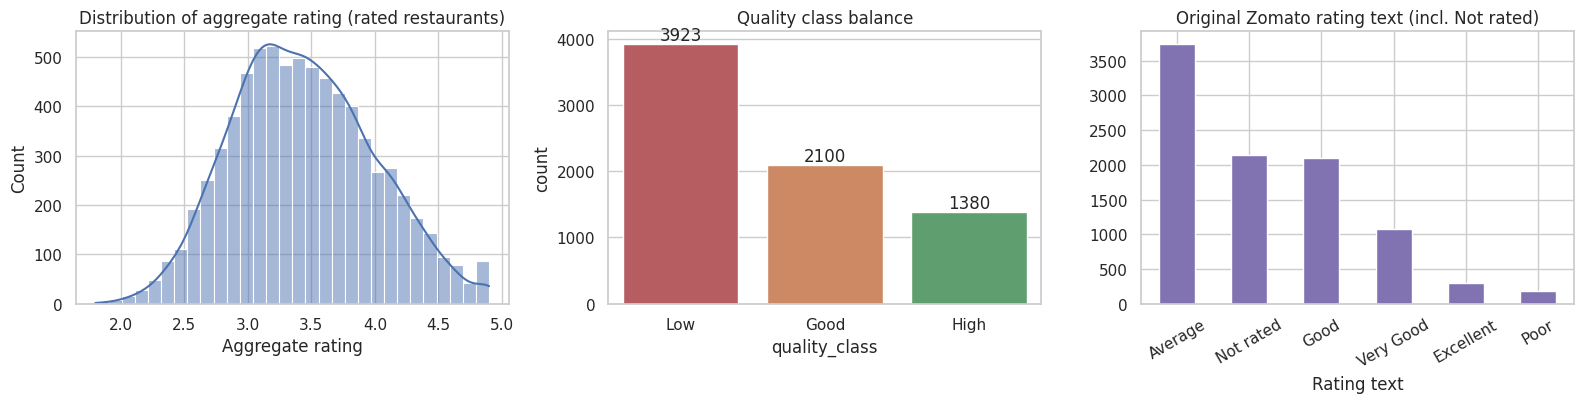

Skewness: 0.231 | Kurtosis: -0.337


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(rated['Aggregate rating'], bins=30, kde=True, ax=ax[0], color='#4c72b0'); ax[0].set_title('Distribution of aggregate rating (rated restaurants)')
order = ['Low','Good','High']
sns.countplot(x='quality_class', data=rated, order=order, ax=ax[1], palette=['#c44e52','#dd8452','#55a868']); ax[1].set_title('Quality class balance')
for p in ax[1].patches: ax[1].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
raw['Rating text'].value_counts().plot.bar(ax=ax[2], color='#8172b2'); ax[2].set_title('Original Zomato rating text (incl. Not rated)'); ax[2].tick_params(axis='x', rotation=30)
savefig('target_distribution')
print('Skewness: %.3f | Kurtosis: %.3f' % (stats.skew(rated['Aggregate rating']), stats.kurtosis(rated['Aggregate rating'])))

### 4.2 Where are the restaurants? Country and city

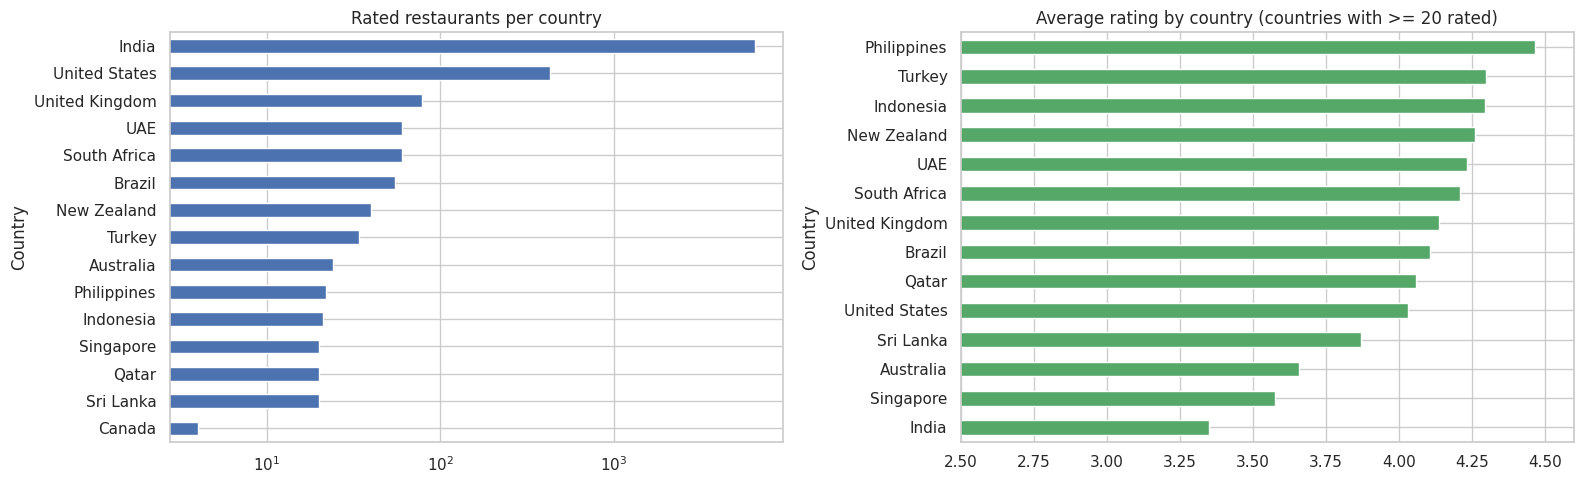

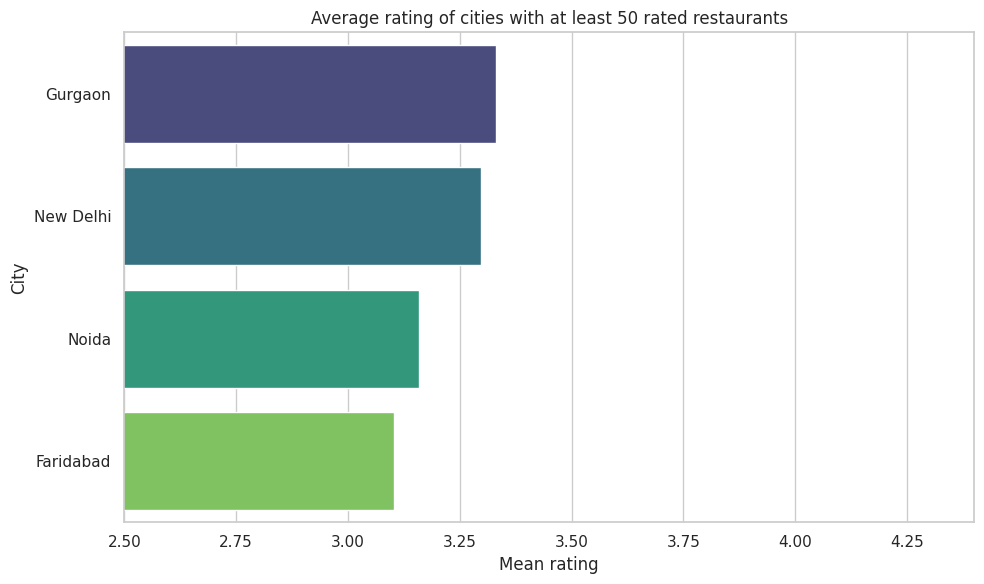

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
cc = rated['Country'].value_counts(); cc.plot.barh(ax=ax[0], color='#4c72b0'); ax[0].invert_yaxis(); ax[0].set_title('Rated restaurants per country'); ax[0].set_xscale('log')
cr = rated.groupby('Country')['Aggregate rating'].agg(['mean','count']).query('count>=20').sort_values('mean')
cr['mean'].plot.barh(ax=ax[1], color='#55a868'); ax[1].set_title('Average rating by country (countries with >= 20 rated)'); ax[1].set_xlim(2.5, 4.6)
savefig('country_overview')
city = rated.groupby('City')['Aggregate rating'].agg(['mean','count']).query('count>=50').sort_values('mean', ascending=False)
plt.figure(figsize=(10,6)); sns.barplot(y=city.index, x=city['mean'], palette='viridis'); plt.xlim(2.5,4.4); plt.title('Average rating of cities with at least 50 rated restaurants'); plt.xlabel('Mean rating')
savefig('city_rating')

### 4.3 Price, services and ratings

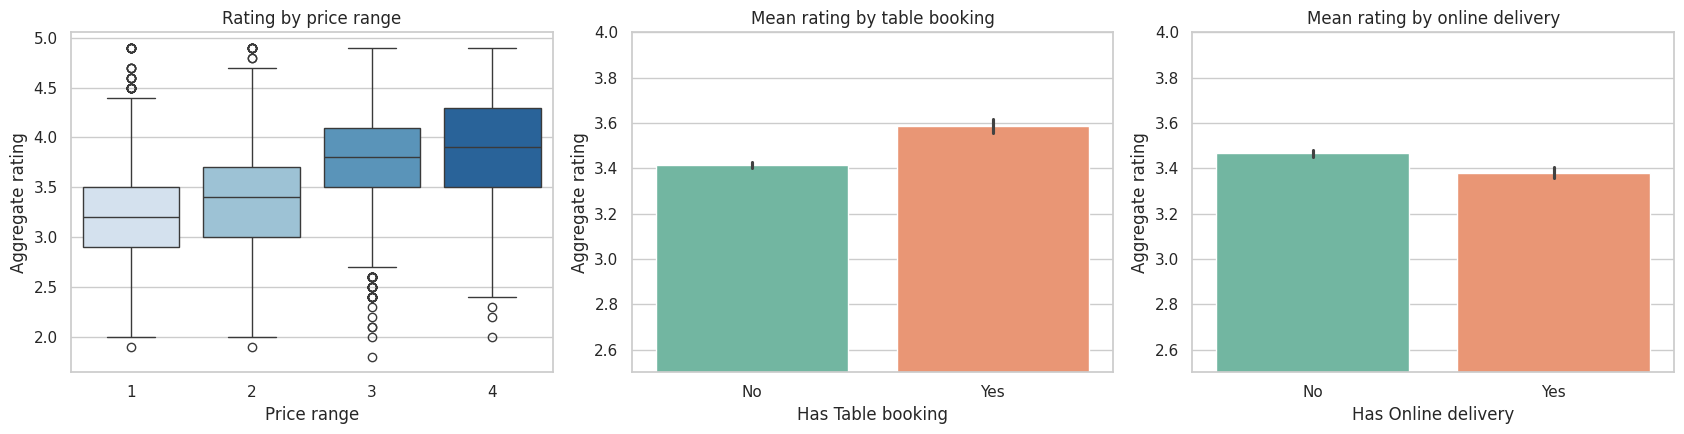

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(x='Price range', y='Aggregate rating', data=rated, ax=ax[0], palette='Blues'); ax[0].set_title('Rating by price range')
sns.barplot(x='Has Table booking', y='Aggregate rating', data=rated, ax=ax[1], palette='Set2', errorbar=('ci',95)); ax[1].set_xticklabels(['No','Yes']); ax[1].set_title('Mean rating by table booking')
sns.barplot(x='Has Online delivery', y='Aggregate rating', data=rated, ax=ax[2], palette='Set2', errorbar=('ci',95)); ax[2].set_xticklabels(['No','Yes']); ax[2].set_title('Mean rating by online delivery')
for a in ax[1:]: a.set_ylim(2.5, 4.0)
savefig('price_services')

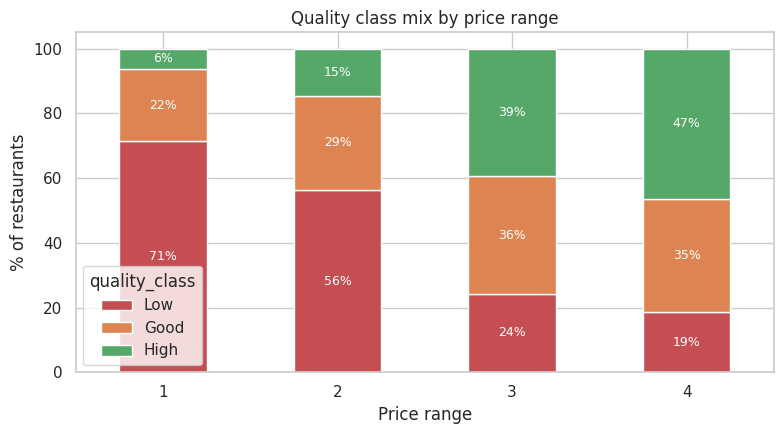

In [13]:
ct = pd.crosstab(rated['Price range'], rated['quality_class'], normalize='index')[['Low','Good','High']]*100
ax = ct.plot.bar(stacked=True, figsize=(8,4.5), color=['#c44e52','#dd8452','#55a868']); plt.ylabel('% of restaurants'); plt.title('Quality class mix by price range'); plt.xticks(rotation=0)
for c in ax.containers: ax.bar_label(c, fmt='%.0f%%', label_type='center', color='white', fontsize=9)
savefig('price_vs_quality_stacked')

### 4.4 Votes (customer engagement)

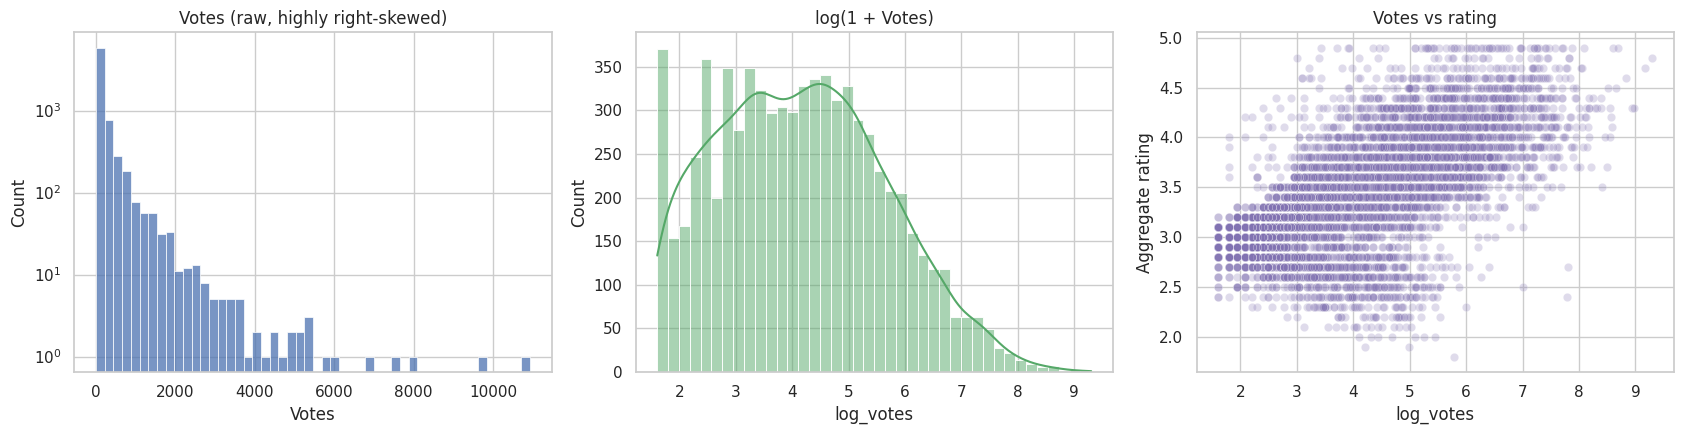

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(rated['Votes'], bins=50, ax=ax[0], color='#4c72b0'); ax[0].set_title('Votes (raw, highly right-skewed)'); ax[0].set_yscale('log')
sns.histplot(rated['log_votes'], bins=40, kde=True, ax=ax[1], color='#55a868'); ax[1].set_title('log(1 + Votes)')
sns.scatterplot(x='log_votes', y='Aggregate rating', data=rated, alpha=.25, ax=ax[2], color='#8172b2'); ax[2].set_title('Votes vs rating')
savefig('votes')

### 4.5 Cuisines

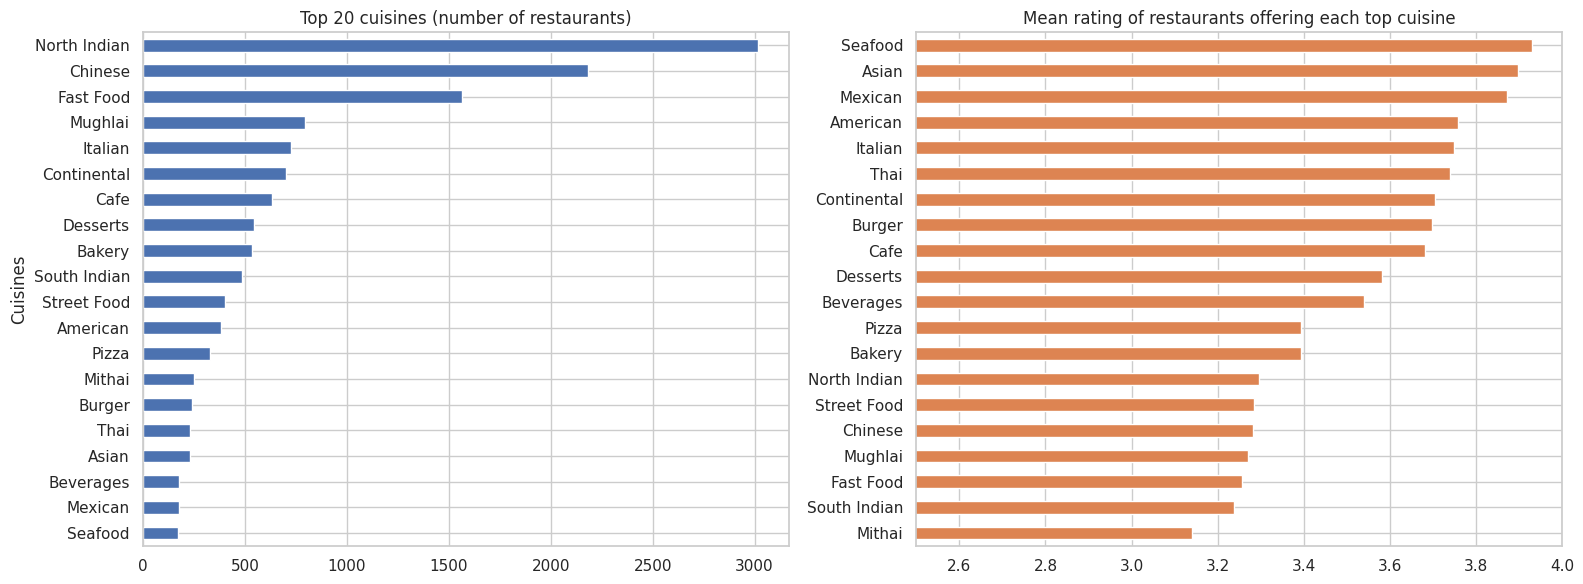

In [15]:
cu = {c: rated.loc[rated['cu_'+c.replace(' ','_')]==1, 'Aggregate rating'].mean() for c in TOP_CUIS}
cu = pd.Series(cu).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
cuis_counts.head(20).sort_values().plot.barh(ax=ax[0], color='#4c72b0'); ax[0].set_title('Top 20 cuisines (number of restaurants)')
cu.plot.barh(ax=ax[1], color='#dd8452'); ax[1].set_title('Mean rating of restaurants offering each top cuisine'); ax[1].set_xlim(2.5, 4.0)
savefig('cuisines')

### 4.6 Geographic pattern

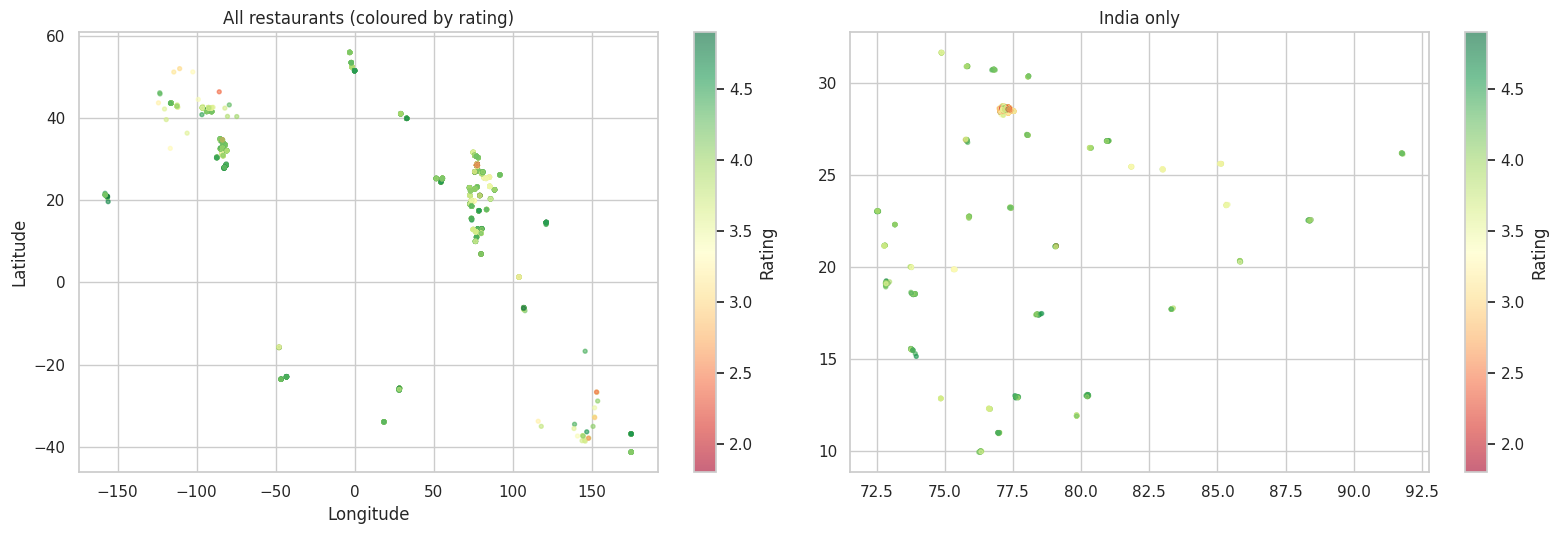

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
g = rated[(rated['Longitude']!=0)&(rated['Latitude']!=0)]
sc = ax[0].scatter(g['Longitude'], g['Latitude'], c=g['Aggregate rating'], cmap='RdYlGn', s=8, alpha=.6); plt.colorbar(sc, ax=ax[0], label='Rating'); ax[0].set_title('All restaurants (coloured by rating)'); ax[0].set_xlabel('Longitude'); ax[0].set_ylabel('Latitude')
ind = g[g['Country']=='India']; ind = ind[(ind.Longitude.between(68,98))&(ind.Latitude.between(6,37))]
sc2 = ax[1].scatter(ind['Longitude'], ind['Latitude'], c=ind['Aggregate rating'], cmap='RdYlGn', s=8, alpha=.6); plt.colorbar(sc2, ax=ax[1], label='Rating'); ax[1].set_title('India only')
savefig('geo_map')

### 4.7 Correlation analysis

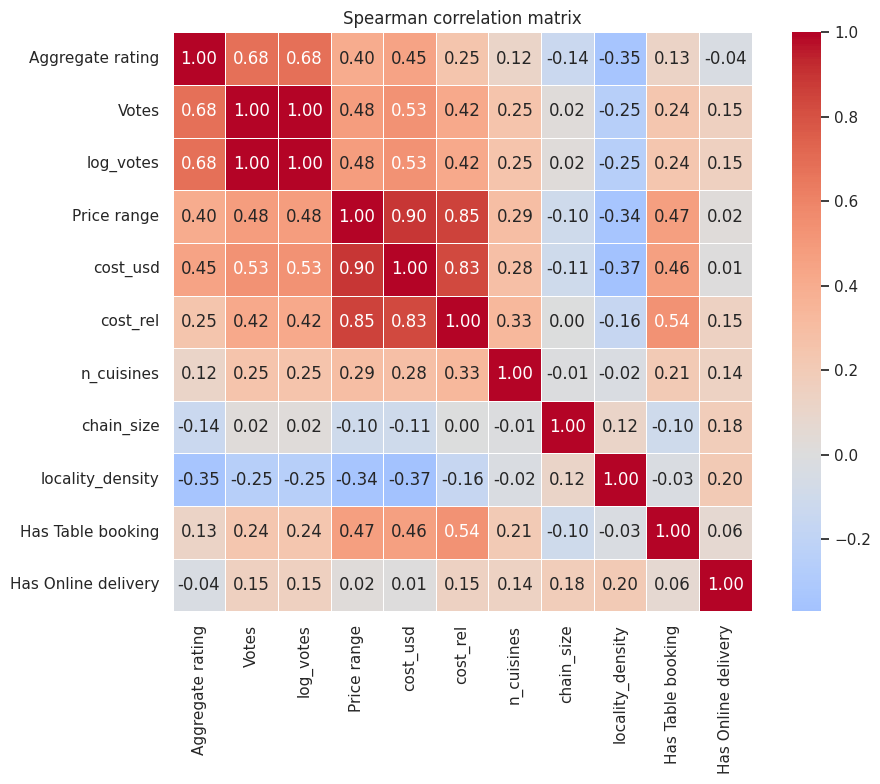

Votes                  0.682
log_votes              0.682
cost_usd               0.449
Price range            0.402
cost_rel               0.248
Has Table booking      0.126
n_cuisines             0.116
Has Online delivery   -0.039
chain_size            -0.138
locality_density      -0.345
Name: Aggregate rating, dtype: float64


In [17]:
num_cols = ['Aggregate rating','Votes','log_votes','Price range','cost_usd','cost_rel','n_cuisines','chain_size','locality_density','Has Table booking','Has Online delivery']
corr = rated[num_cols].corr(method='spearman')
plt.figure(figsize=(10,8)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=.5); plt.title('Spearman correlation matrix')
savefig('correlation_heatmap')
print(corr['Aggregate rating'].drop('Aggregate rating').sort_values(ascending=False).round(3))

## 5. Statistical Analysis
We use non-parametric tests where normality does not hold (ratings are not normally distributed), and always report an **effect size** because with thousands of rows tiny differences become "significant".

In [18]:
results = []
alpha = 0.05
r = rated['Aggregate rating']

# T1 Normality of the target
sw = stats.shapiro(r.sample(5000, random_state=1)); nt = stats.normaltest(r)
print(f'T1 Normality: Shapiro-Wilk W={sw.statistic:.4f}, p={sw.pvalue:.2e} | D\'Agostino K2={nt.statistic:.1f}, p={nt.pvalue:.2e}  -> not normal, use non-parametric tests')

# T2 Mann-Whitney U : rating vs table booking
a = rated.loc[rated['Has Table booking']==1,'Aggregate rating']; b = rated.loc[rated['Has Table booking']==0,'Aggregate rating']
u = stats.mannwhitneyu(a, b); rbc = 1 - 2*u.statistic/(len(a)*len(b))
cohen_d = (a.mean()-b.mean())/np.sqrt((a.var()+b.var())/2)
results.append(['Mann-Whitney U','Rating: table booking Yes vs No', u.pvalue, f'Cohen d = {cohen_d:.2f}', f'mean {a.mean():.2f} vs {b.mean():.2f}'])

# T3 Mann-Whitney U : online delivery
a = rated.loc[rated['Has Online delivery']==1,'Aggregate rating']; b = rated.loc[rated['Has Online delivery']==0,'Aggregate rating']
u = stats.mannwhitneyu(a, b); cohen_d = (a.mean()-b.mean())/np.sqrt((a.var()+b.var())/2)
results.append(['Mann-Whitney U','Rating: online delivery Yes vs No', u.pvalue, f'Cohen d = {cohen_d:.2f}', f'mean {a.mean():.2f} vs {b.mean():.2f}'])

# T4 Kruskal-Wallis : rating across price range
groups = [g['Aggregate rating'].values for _, g in rated.groupby('Price range')]
kw = stats.kruskal(*groups); eps2 = (kw.statistic - len(groups) + 1)/(len(rated) - len(groups))
results.append(['Kruskal-Wallis','Rating across 4 price ranges', kw.pvalue, f'epsilon^2 = {eps2:.3f}', ' / '.join(f'{g.mean():.2f}' for g in groups)])

# T5 Kruskal-Wallis : rating across countries (>=20 rated)
big = rated.groupby('Country').filter(lambda d: len(d) >= 20)
groups = [g['Aggregate rating'].values for _, g in big.groupby('Country')]
kw = stats.kruskal(*groups); eps2 = (kw.statistic - len(groups) + 1)/(len(big) - len(groups))
results.append(['Kruskal-Wallis','Rating across countries', kw.pvalue, f'epsilon^2 = {eps2:.3f}', f'{len(groups)} countries'])

# T6 Spearman : votes vs rating, cost vs rating
for col in ['Votes','cost_rel','n_cuisines','chain_size']:
    rho, p = stats.spearmanr(rated[col], rated['Aggregate rating'])
    results.append(['Spearman correlation', f'{col} vs rating', p, f'rho = {rho:.3f}', ''])

# T7 Chi-square (+ Cramer's V) : quality class vs services / price range
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum(); k = min(ct.shape)-1
    return np.sqrt(chi2/(n*k))
for col in ['Has Table booking','Has Online delivery','Is delivering now','Price range']:
    ct = pd.crosstab(rated[col], rated['quality_class']); chi2, p, dof, _ = stats.chi2_contingency(ct)
    results.append(['Chi-square', f'Quality class vs {col}', p, f"Cramer's V = {cramers_v(ct):.3f}", f'dof={dof}'])

# T8 Spearman between price range & table booking (service bundle)
stat_table = pd.DataFrame(results, columns=['Test','Hypothesis (H0: no difference / association)','p-value','Effect size','Detail'])
stat_table['Decision (alpha=0.05)'] = np.where(stat_table['p-value']<alpha, 'Reject H0', 'Fail to reject H0')
stat_table['p-value'] = stat_table['p-value'].apply(lambda v: f'{v:.2e}')
stat_table.to_csv('outputs/statistical_tests.csv', index=False)
display(stat_table)

T1 Normality: Shapiro-Wilk W=0.9898, p=1.61e-18 | D'Agostino K2=115.0, p=1.06e-25  -> not normal, use non-parametric tests


,Test,Hypothesis (H0: no difference / association),p-value,Effect size,Detail,Decision (alpha=0.05)
0,Mann-Whitney U,Rating: table booking Yes vs No,1.55e-27,Cohen d = 0.32,mean 3.59 vs 3.41,Reject H0
1,Mann-Whitney U,Rating: online delivery Yes vs No,8.66e-04,Cohen d = -0.16,mean 3.38 vs 3.47,Reject H0
2,Kruskal-Wallis,Rating across 4 price ranges,3.25e-287,epsilon^2 = 0.179,3.24 / 3.38 / 3.78 / 3.89,Reject H0
3,Kruskal-Wallis,Rating across countries,2.08e-262,epsilon^2 = 0.169,14 countries,Reject H0
4,Spearman correlation,Votes vs rating,0.00e+00,rho = 0.682,,Reject H0
5,Spearman correlation,cost_rel vs rating,1.51e-104,rho = 0.248,,Reject H0
6,Spearman correlation,n_cuisines vs rating,1.68e-23,rho = 0.116,,Reject H0
7,Spearman correlation,chain_size vs rating,5.42e-33,rho = -0.138,,Reject H0
8,Chi-square,Quality class vs Has Table booking,6.08e-28,Cramer's V = 0.130,dof=2,Reject H0
9,Chi-square,Quality class vs Has Online delivery,1.32e-22,Cramer's V = 0.117,dof=2,Reject H0


**Interpretation**

* Ratings are **not normally distributed**, so non-parametric tests were used.
* Table booking, price range and country show statistically significant relationships with ratings, and the effect sizes tell us which of them are also practically meaningful (see *Effect size* column).
* The strongest single association is between **votes (engagement)** and rating, which is why Scenario A (with votes) performs better than Scenario B.
* Correlation does not mean causation: higher-priced restaurants may be rated higher because of who chooses to review them.

## 6. Predictive Modelling

### 6.1 Setup
* Train/test split **80/20, stratified** by class (the test set is never touched during tuning).
* All preprocessing is inside a scikit-learn `Pipeline`, so no information leaks from the test set.
* **Scenario A** = static features + votes; **Scenario B** = static features only.
* Models: Logistic Regression (baseline), Decision Tree, Random Forest, Gradient Boosting, XGBoost and a Neural Network (MLP).
* Metrics: Accuracy, Macro-F1 (treats all classes equally), Weighted-F1, ROC-AUC (one-vs-rest).

In [19]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize
from xgboost import XGBClassifier

cuisine_cols = ['cu_'+c.replace(' ','_') for c in TOP_CUIS]
num_static = ['Price range','cost_rel','cost_usd_log','n_cuisines','chain_size','locality_density','Longitude','Latitude']
bin_cols   = ['Has Table booking','Has Online delivery','Is delivering now'] + cuisine_cols
cat_cols   = ['Country','city_grp']
FEATS_B = num_static + bin_cols + cat_cols
FEATS_A = FEATS_B + ['log_votes']

def make_pre(features):
    nums = [c for c in features if c in num_static + ['log_votes']]
    bins = [c for c in features if c in bin_cols]
    return ColumnTransformer([('num', StandardScaler(), nums), ('bin', 'passthrough', bins),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

y = rated['y']
idx_train, idx_test = train_test_split(rated.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
Xtr_all, Xte_all, ytr, yte = rated.loc[idx_train], rated.loc[idx_test], y.loc[idx_train], y.loc[idx_test]
print('Train:', len(Xtr_all), '| Test:', len(Xte_all))
print('Train class share:', ytr.value_counts(normalize=True).sort_index().round(3).to_dict())

Train: 5922 | Test: 1481
Train class share: {0: 0.53, 1: 0.284, 2: 0.186}


In [20]:
def get_models():
    return {
      'Baseline (majority)': DummyClassifier(strategy='most_frequent'),
      'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced', C=1.0),
      'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=RANDOM_STATE),
      'Random Forest': RandomForestClassifier(n_estimators=250, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE),
      'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.08, random_state=RANDOM_STATE),
      'XGBoost': XGBClassifier(n_estimators=250, max_depth=4, learning_rate=0.08, subsample=0.9, colsample_bytree=0.8, eval_metric='mlogloss', n_jobs=-1, random_state=RANDOM_STATE),
      'Neural Network (MLP)': MLPClassifier(hidden_layer_sizes=(64,32), alpha=1e-3, early_stopping=True, max_iter=300, random_state=RANDOM_STATE),
    }

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for scen, feats in [('A (with votes)', FEATS_A), ('B (no votes)', FEATS_B)]:
    for name, mdl in get_models().items():
        pipe = Pipeline([('pre', make_pre(feats)), ('clf', mdl)])
        cv = cross_validate(pipe, Xtr_all[feats], ytr, cv=skf, scoring=['accuracy','f1_macro'], n_jobs=1)
        cv_rows.append([scen, name, cv['test_accuracy'].mean(), cv['test_accuracy'].std(), cv['test_f1_macro'].mean(), cv['test_f1_macro'].std()])
        print(f'{scen:15s} {name:22s} acc={cv["test_accuracy"].mean():.3f} (+/-{cv["test_accuracy"].std():.3f})  macroF1={cv["test_f1_macro"].mean():.3f}')
cv_df = pd.DataFrame(cv_rows, columns=['Scenario','Model','CV Accuracy','Acc std','CV Macro-F1','F1 std'])
cv_df.to_csv('outputs/cv_results.csv', index=False)

A (with votes)  Baseline (majority)    acc=0.530 (+/-0.000)  macroF1=0.231


A (with votes)  Logistic Regression    acc=0.732 (+/-0.013)  macroF1=0.698


A (with votes)  Decision Tree          acc=0.697 (+/-0.027)  macroF1=0.672


A (with votes)  Random Forest          acc=0.755 (+/-0.011)  macroF1=0.719


A (with votes)  Gradient Boosting      acc=0.760 (+/-0.010)  macroF1=0.719


...

B (no votes)    Logistic Regression    acc=0.651 (+/-0.015)  macroF1=0.608
B (no votes)    Decision Tree          acc=0.644 (+/-0.011)  macroF1=0.608


B (no votes)    Random Forest          acc=0.697 (+/-0.010)  macroF1=0.650


B (no votes)    Gradient Boosting      acc=0.704 (+/-0.016)  macroF1=0.649


B (no votes)    XGBoost                acc=0.705 (+/-0.016)  macroF1=0.652


B (no votes)    Neural Network (MLP)   acc=0.672 (+/-0.013)  macroF1=0.608


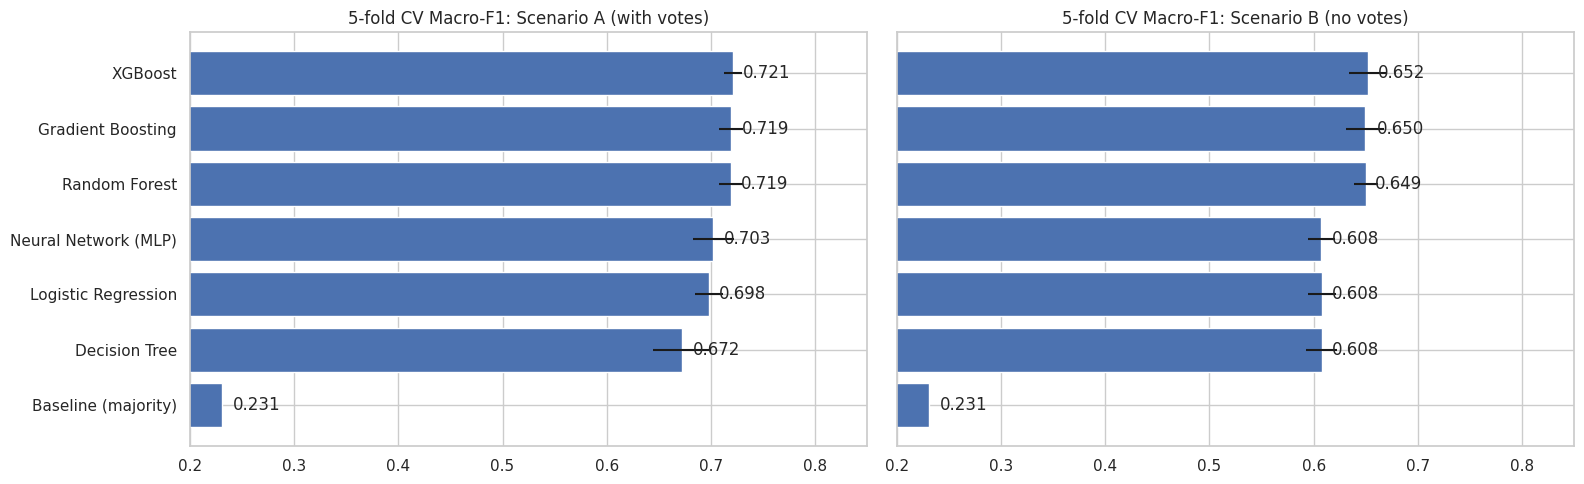

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for a, scen in zip(ax, ['A (with votes)', 'B (no votes)']):
    d = cv_df[cv_df['Scenario']==scen].sort_values('CV Macro-F1')
    a.barh(d['Model'], d['CV Macro-F1'], xerr=d['F1 std'], color='#4c72b0'); a.set_title(f'5-fold CV Macro-F1: Scenario {scen}'); a.set_xlim(0.2, 0.85)
    for i, v in enumerate(d['CV Macro-F1']): a.text(v+0.01, i, f'{v:.3f}', va='center')
savefig('cv_model_comparison')

### 6.2 Hyperparameter tuning
The two best tree-ensemble families (Random Forest and XGBoost) are tuned with `RandomizedSearchCV` (3-fold, Macro-F1) in each scenario. The final model per scenario is the one with the best cross-validated score. **Only the training set is used here.**

In [22]:
rf_space  = {'clf__n_estimators':[200,300,400], 'clf__max_depth':[None,12,20], 'clf__min_samples_leaf':[1,2,4], 'clf__max_features':['sqrt',0.3]}
xgb_space = {'clf__n_estimators':[150,250,350], 'clf__max_depth':[3,4,5,6], 'clf__learning_rate':[0.03,0.06,0.1], 'clf__subsample':[0.7,0.9,1.0], 'clf__colsample_bytree':[0.6,0.8,1.0]}
tuned = {}
for scen, feats in [('A', FEATS_A), ('B', FEATS_B)]:
    best = None
    for nm, est, space in [('Random Forest', RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE), rf_space),
                           ('XGBoost', XGBClassifier(eval_metric='mlogloss', n_jobs=-1, random_state=RANDOM_STATE), xgb_space)]:
        pipe = Pipeline([('pre', make_pre(feats)), ('clf', est)])
        rs = RandomizedSearchCV(pipe, space, n_iter=8, scoring='f1_macro', cv=3, random_state=RANDOM_STATE, n_jobs=1)
        rs.fit(Xtr_all[feats], ytr)
        print(f'Scenario {scen} | {nm:13s} best CV macro-F1 = {rs.best_score_:.4f} | {rs.best_params_}')
        if best is None or rs.best_score_ > best[1]: best = (nm, rs.best_score_, rs.best_estimator_, rs.best_params_)
    tuned[scen] = best
    print(f'  --> Selected for scenario {scen}: {best[0]}\n')

Scenario A | Random Forest best CV macro-F1 = 0.7210 | {'clf__n_estimators': 300, 'clf__min_samples_leaf': 2, 'clf__max_features': 0.3, 'clf__max_depth': 20}


Scenario A | XGBoost       best CV macro-F1 = 0.7202 | {'clf__subsample': 0.7, 'clf__n_estimators': 350, 'clf__max_depth': 5, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.8}
  --> Selected for scenario A: Random Forest



Scenario B | Random Forest best CV macro-F1 = 0.6496 | {'clf__n_estimators': 300, 'clf__min_samples_leaf': 1, 'clf__max_features': 'sqrt', 'clf__max_depth': 12}


Scenario B | XGBoost       best CV macro-F1 = 0.6494 | {'clf__subsample': 0.9, 'clf__n_estimators': 350, 'clf__max_depth': 4, 'clf__learning_rate': 0.1, 'clf__colsample_bytree': 0.8}
  --> Selected for scenario B: Random Forest



### 6.3 Final evaluation on the unseen test set

In [23]:
labels = ['Low','Good','High']
final = {}
for scen, feats in [('A', FEATS_A), ('B', FEATS_B)]:
    nm, _, model, params = tuned[scen]
    model.fit(Xtr_all[feats], ytr)
    pred = model.predict(Xte_all[feats]); proba = model.predict_proba(Xte_all[feats])
    acc = accuracy_score(yte, pred); mf1 = f1_score(yte, pred, average='macro'); wf1 = f1_score(yte, pred, average='weighted')
    auc_ovr = roc_auc_score(yte, proba, multi_class='ovr')
    final[scen] = dict(model=nm, accuracy=acc, macro_f1=mf1, weighted_f1=wf1, roc_auc=auc_ovr, pred=pred, proba=proba, params=params)
    print(f'=== Scenario {scen} | {nm} ===')
    print(f'Accuracy={acc:.4f}  Macro-F1={mf1:.4f}  Weighted-F1={wf1:.4f}  ROC-AUC(ovr)={auc_ovr:.4f}')
    print(classification_report(yte, pred, target_names=labels, digits=3))
    joblib.dump({'model': model, 'features': feats, 'labels': labels}, f'models/best_model_scenario_{scen}.joblib')

# baseline on test for comparison
base_pred = DummyClassifier(strategy='most_frequent').fit(Xtr_all[FEATS_B], ytr).predict(Xte_all[FEATS_B])
print('Majority baseline test accuracy: %.3f | macro-F1: %.3f' % (accuracy_score(yte, base_pred), f1_score(yte, base_pred, average='macro')))

=== Scenario A | Random Forest ===
Accuracy=0.7711  Macro-F1=0.7416  Weighted-F1=0.7724  ROC-AUC(ovr)=0.9056
              precision    recall  f1-score   support

         Low      0.871     0.857     0.864       785
        Good      0.611     0.640     0.626       420
        High      0.746     0.725     0.735       276

    accuracy                          0.771      1481
   macro avg      0.743     0.741     0.742      1481
weighted avg      0.774     0.771     0.772      1481



=== Scenario B | Random Forest ===
Accuracy=0.6975  Macro-F1=0.6518  Weighted-F1=0.6861  ROC-AUC(ovr)=0.8362
              precision    recall  f1-score   support

         Low      0.769     0.855     0.810       785
        Good      0.511     0.395     0.446       420
        High      0.690     0.710     0.700       276

    accuracy                          0.698      1481
   macro avg      0.657     0.653     0.652      1481
weighted avg      0.681     0.698     0.686      1481

Majority baseline test accuracy: 0.530 | macro-F1: 0.231


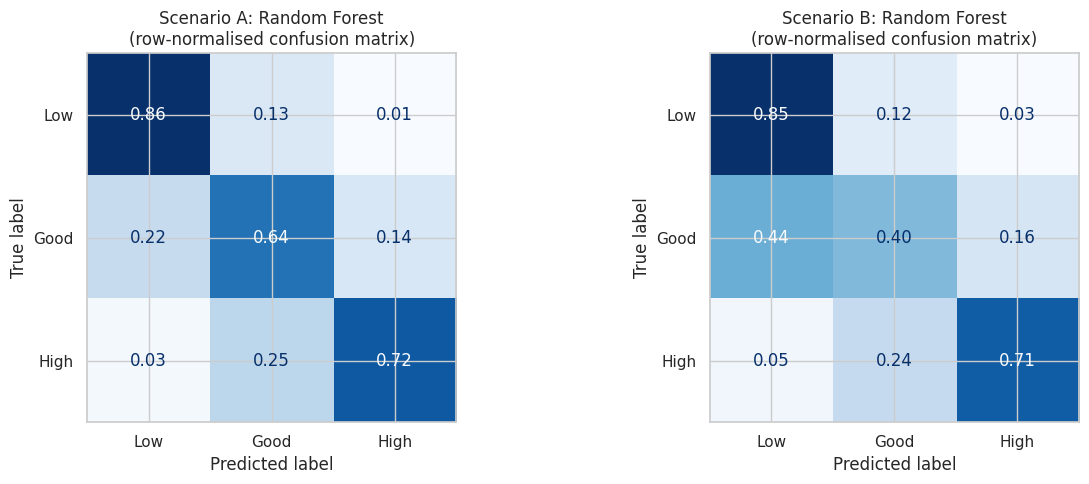

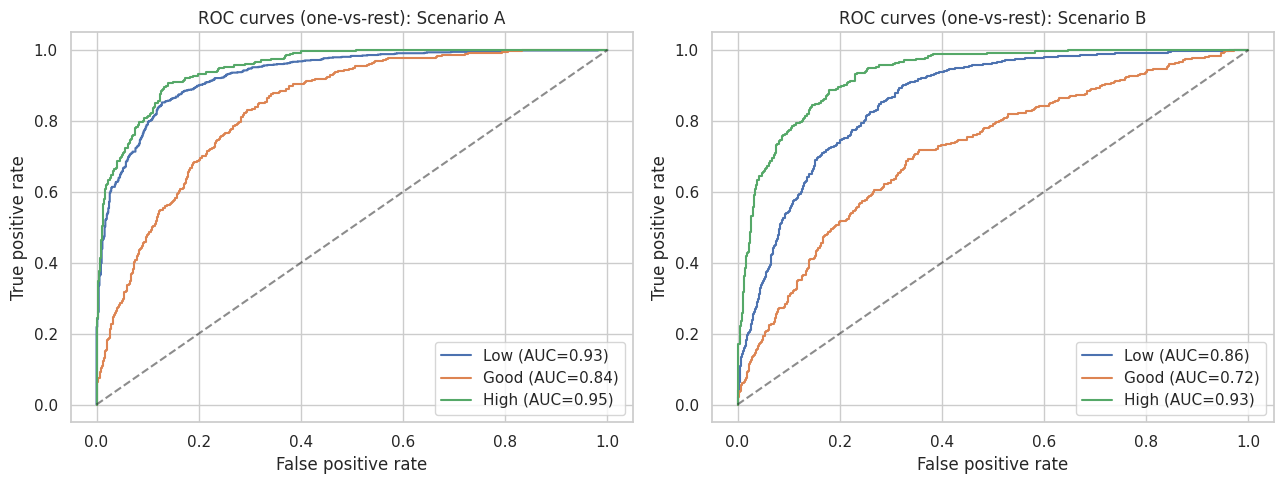

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, scen in zip(ax, ['A','B']):
    cm = confusion_matrix(yte, final[scen]['pred'], normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=a, cmap='Blues', values_format='.2f', colorbar=False)
    a.set_title(f"Scenario {scen}: {final[scen]['model']}\n(row-normalised confusion matrix)")
savefig('confusion_matrices')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
Yb = label_binarize(yte, classes=[0,1,2])
for a, scen in zip(ax, ['A','B']):
    for i, lab in enumerate(labels):
        fpr, tpr, _ = roc_curve(Yb[:, i], final[scen]['proba'][:, i]); a.plot(fpr, tpr, label=f'{lab} (AUC={auc(fpr,tpr):.2f})')
    a.plot([0,1],[0,1],'k--', alpha=.5); a.set_title(f'ROC curves (one-vs-rest): Scenario {scen}'); a.set_xlabel('False positive rate'); a.set_ylabel('True positive rate'); a.legend()
savefig('roc_curves')

### 6.4 Which factors drive restaurant quality? (Permutation importance on the test set)

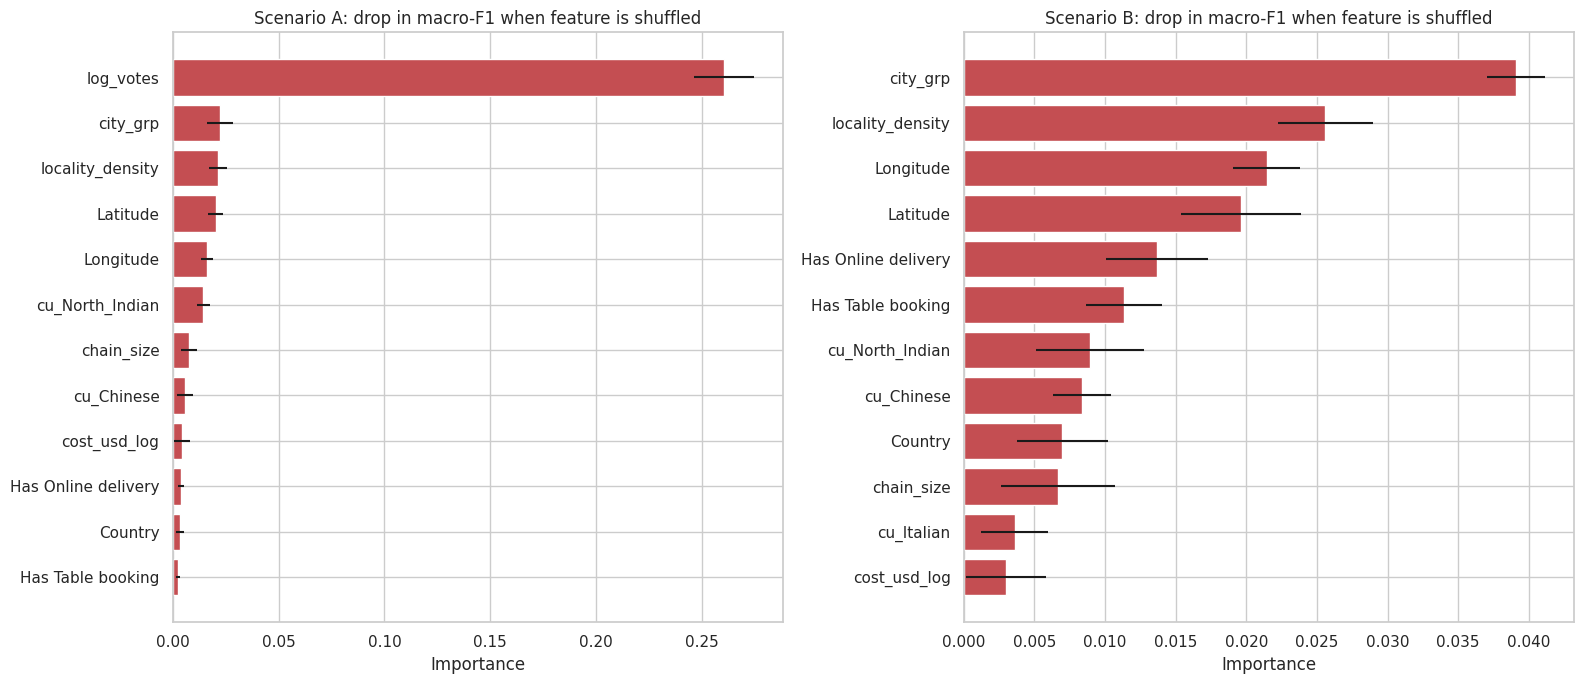

Top 8 drivers, Scenario A: ['log_votes', 'city_grp', 'locality_density', 'Latitude', 'Longitude', 'cu_North_Indian', 'chain_size', 'cu_Chinese']
Top 8 drivers, Scenario B: ['city_grp', 'locality_density', 'Longitude', 'Latitude', 'Has Online delivery', 'Has Table booking', 'cu_North_Indian', 'cu_Chinese']


In [25]:
from sklearn.inspection import permutation_importance
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
imp_tables = {}
for a, scen, feats in zip(ax, ['A','B'], [FEATS_A, FEATS_B]):
    model = joblib.load(f'models/best_model_scenario_{scen}.joblib')['model']
    pi = permutation_importance(model, Xte_all[feats], yte, scoring='f1_macro', n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
    imp = pd.DataFrame({'feature': feats, 'importance': pi.importances_mean, 'std': pi.importances_std}).sort_values('importance', ascending=False)
    imp_tables[scen] = imp; imp.to_csv(f'outputs/permutation_importance_{scen}.csv', index=False)
    top = imp.head(12).iloc[::-1]
    a.barh(top['feature'], top['importance'], xerr=top['std'], color='#c44e52'); a.set_title(f'Scenario {scen}: drop in macro-F1 when feature is shuffled'); a.set_xlabel('Importance')
savefig('feature_importance')
print('Top 8 drivers, Scenario A:', imp_tables['A'].head(8)['feature'].tolist())
print('Top 8 drivers, Scenario B:', imp_tables['B'].head(8)['feature'].tolist())

## 7. Regression: Predicting the exact rating
Besides the class, we also predict the numeric rating (1.8 to 4.9). Models: Linear Regression (baseline), Random Forest, XGBoost.

In [26]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ytr_r, yte_r = Xtr_all['Aggregate rating'], Xte_all['Aggregate rating']
reg_rows = []; reg_pred = {}
for scen, feats in [('A (with votes)', FEATS_A), ('B (no votes)', FEATS_B)]:
    regs = {'Baseline (mean)': DummyRegressor(), 'Ridge Regression': Ridge(alpha=3.0),
            'Random Forest': RandomForestRegressor(n_estimators=250, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
            'XGBoost': XGBRegressor(n_estimators=350, max_depth=4, learning_rate=0.05, subsample=0.9, colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE)}
    for nm, reg in regs.items():
        p = Pipeline([('pre', make_pre(feats)), ('reg', reg)]).fit(Xtr_all[feats], ytr_r); pr = p.predict(Xte_all[feats])
        reg_rows.append([scen, nm, np.sqrt(mean_squared_error(yte_r, pr)), mean_absolute_error(yte_r, pr), r2_score(yte_r, pr)])
        reg_pred[(scen, nm)] = pr
reg_df = pd.DataFrame(reg_rows, columns=['Scenario','Model','RMSE','MAE','R2']); reg_df.to_csv('outputs/regression_results.csv', index=False)
display(reg_df.round(4))

,Scenario,Model,RMSE,MAE,R2
0,A (with votes),Baseline (mean),0.5530,0.4485,-0.0009
1,A (with votes),Ridge Regression,0.3448,0.2585,0.6108
2,A (with votes),Random Forest,0.3289,0.2422,0.6460
3,A (with votes),XGBoost,0.3208,0.2395,0.6631
4,B (no votes),Baseline (mean),0.5530,0.4485,-0.0009
5,B (no votes),Ridge Regression,0.3996,0.3136,0.4775
6,B (no votes),Random Forest,0.3657,0.2855,0.5623
7,B (no votes),XGBoost,0.3604,0.2840,0.5749


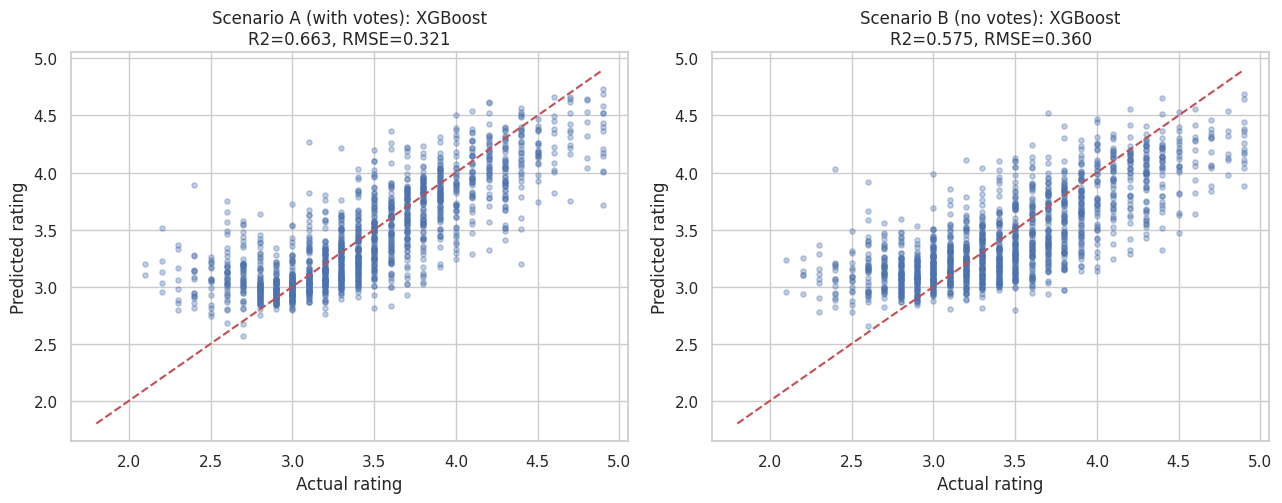

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for a, scen in zip(ax, ['A (with votes)', 'B (no votes)']):
    sub = reg_df[(reg_df['Scenario']==scen) & (reg_df['Model']!='Baseline (mean)')].sort_values('RMSE'); bm = sub.iloc[0]['Model']
    a.scatter(yte_r, reg_pred[(scen, bm)], alpha=.35, s=14, color='#4c72b0'); a.plot([1.8,4.9],[1.8,4.9],'r--')
    a.set_title(f'Scenario {scen}: {bm}\nR2={sub.iloc[0]["R2"]:.3f}, RMSE={sub.iloc[0]["RMSE"]:.3f}'); a.set_xlabel('Actual rating'); a.set_ylabel('Predicted rating')
savefig('regression_actual_vs_pred')

## 8. Applying the model to unrated restaurants (societal use-case)

predicted_quality
Low     2075
Good      61
High      12
Name: count, dtype: int64

Top 10 unrated restaurants most likely to be rated High quality:


,Restaurant Name,City,Country,Cuisines,Price range,Has Table booking,Has Online delivery,predicted_quality,prob_high
58,Quiosque Chopp Brahma,Rio de Janeiro,Brazil,"Bar Food, Brazilian",3,0,0,High,0.823882
239,Los Agaves,Davenport,United States,Mexican,2,0,0,High,0.800884
77,Divino Fog��o,S��o Paulo,Brazil,"Brazilian, Mineira",3,0,0,High,0.786775
238,Frick's Tap,Davenport,United States,"American, Bar Food, BBQ",2,0,0,High,0.735955
78,Super Grill,S��o Paulo,Brazil,Brazilian,2,0,0,High,0.662496
69,Cantinho da Gula,S��o Paulo,Brazil,Brazilian,2,0,0,High,0.652386
9351,Damascena Coffee House,Birmingham,United Kingdom,"Greek, Mediterranean, Middle Eastern",2,0,0,High,0.652258
4812,Chez Jerome - Q Cafe,New Delhi,India,"Cafe, French",3,1,0,High,0.487342
3971,Shi Cafe,New Delhi,India,"Cafe, Mexican, Continental",3,0,0,High,0.465265
901,TcozY,Faridabad,India,Cafe,3,0,0,High,0.425224


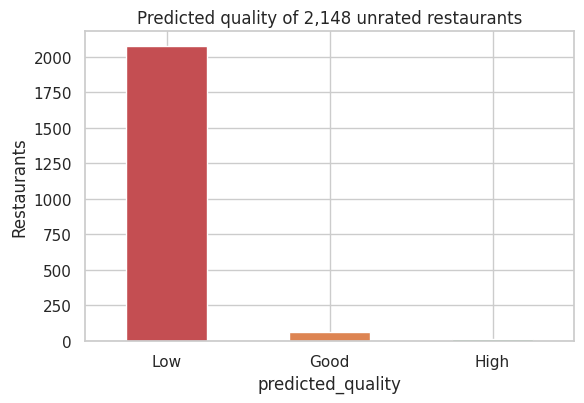

In [28]:
art = joblib.load('models/best_model_scenario_B.joblib'); mB = art['model']
pred_un = mB.predict(unrated[FEATS_B]); proba_un = mB.predict_proba(unrated[FEATS_B])
unrated = unrated.assign(predicted_quality=[labels[i] for i in pred_un], prob_low=proba_un[:,0], prob_good=proba_un[:,1], prob_high=proba_un[:,2])
print(unrated['predicted_quality'].value_counts())
cols = ['Restaurant Name','City','Country','Cuisines','Price range','Has Table booking','Has Online delivery','predicted_quality','prob_high']
unrated[cols].sort_values('prob_high', ascending=False).to_csv('outputs/unrated_restaurant_predictions.csv', index=False)
print('\nTop 10 unrated restaurants most likely to be rated High quality:')
display(unrated[cols].sort_values('prob_high', ascending=False).head(10))
plt.figure(figsize=(6,4.2)); unrated['predicted_quality'].value_counts().reindex(labels).plot.bar(color=['#c44e52','#dd8452','#55a868']); plt.title('Predicted quality of 2,148 unrated restaurants'); plt.xticks(rotation=0); plt.ylabel('Restaurants')
savefig('unrated_predictions')

## 9. Objective Check and Summary

In [29]:
A, B = final['A'], final['B']
reg_A = reg_df[(reg_df['Scenario']=='A (with votes)') & (reg_df['Model']!='Baseline (mean)')].sort_values('RMSE').iloc[0]
checks = [
 ('O1', '0 missing values and 0 duplicate IDs in modelling table', rated.isna().sum().sum()==0 and rated['Restaurant ID'].duplicated().sum()==0, f"missing={rated.isna().sum().sum()}, duplicates={rated['Restaurant ID'].duplicated().sum()}"),
 ('O2', '>= 10 visualisations and >= 5 hypothesis tests', FIG >= 10 and len(stat_table) >= 5, f'figures so far={FIG}, tests={len(stat_table)}'),
 ('O3', 'Scenario A: Macro-F1 >= 0.70 and Accuracy >= 0.70', A['macro_f1']>=0.70 and A['accuracy']>=0.70, f"Macro-F1={A['macro_f1']:.3f}, Accuracy={A['accuracy']:.3f} ({A['model']})"),
 ('O4', 'Scenario B: Macro-F1 >= 0.58', B['macro_f1']>=0.58, f"Macro-F1={B['macro_f1']:.3f}, Accuracy={B['accuracy']:.3f} ({B['model']})"),
 ('O5', 'Regression A: RMSE <= 0.40 and R2 >= 0.50', reg_A['RMSE']<=0.40 and reg_A['R2']>=0.50, f"RMSE={reg_A['RMSE']:.3f}, R2={reg_A['R2']:.3f} ({reg_A['Model']})"),
 ('O6', 'Permutation importance on held-out data', True, 'see feature importance figure'),
 ('O7', 'Predictions for all unrated restaurants', len(unrated)==2148 and unrated['predicted_quality'].notna().all(), f'{len(unrated)} restaurants scored'),
]
chk = pd.DataFrame(checks, columns=['Objective','Criterion','Met?','Result']); chk['Met?'] = chk['Met?'].map({True:'YES', False:'NO'})
display(chk)
chk.to_csv('outputs/objective_check.csv', index=False)

summary = {'n_rows_raw': int(len(raw)), 'n_rated': int(len(rated)), 'n_unrated': int(len(unrated)),
           'scenario_A': {k: (float(v) if isinstance(v,(float,np.floating)) else v) for k,v in A.items() if k in ['model','accuracy','macro_f1','weighted_f1','roc_auc']},
           'scenario_B': {k: (float(v) if isinstance(v,(float,np.floating)) else v) for k,v in B.items() if k in ['model','accuracy','macro_f1','weighted_f1','roc_auc']},
           'regression_A_best': {k: (float(v) if not isinstance(v,str) else v) for k,v in reg_A.items()}}
json.dump(summary, open('outputs/summary_metrics.json','w'), indent=2)
print(json.dumps(summary, indent=2))

,Objective,Criterion,Met?,Result
0,O1,0 missing values and 0 duplicate IDs in modell...,YES,"missing=0, duplicates=0"
1,O2,>= 10 visualisations and >= 5 hypothesis tests,YES,"figures so far=15, tests=12"
2,O3,Scenario A: Macro-F1 >= 0.70 and Accuracy >= 0.70,YES,"Macro-F1=0.742, Accuracy=0.771 (Random Forest)"
3,O4,Scenario B: Macro-F1 >= 0.58,YES,"Macro-F1=0.652, Accuracy=0.698 (Random Forest)"
4,O5,Regression A: RMSE <= 0.40 and R2 >= 0.50,YES,"RMSE=0.321, R2=0.663 (XGBoost)"
5,O6,Permutation importance on held-out data,YES,see feature importance figure
6,O7,Predictions for all unrated restaurants,YES,2148 restaurants scored


{
  "n_rows_raw": 9551,
  "n_rated": 7403,
  "n_unrated": 2148,
  "scenario_A": {
    "model": "Random Forest",
    "accuracy": 0.7711006076975017,
    "macro_f1": 0.7416012086537455,
    "weighted_f1": 0.7723625463841269,
    "roc_auc": 0.9056087494777261
  },
  "scenario_B": {
    "model": "Random Forest",
    "accuracy": 0.6975016880486158,
    "macro_f1": 0.6518449962804399,
    "weighted_f1": 0.6861156300605205,
    "roc_auc": 0.8362241185622604
  },
  "regression_A_best": {
    "Scenario": "A (with votes)",
    "Model": "XGBoost",
    "RMSE": 0.32082530239619883,
    "MAE": 0.23947771930115036,
    "R2": 0.6631384373570709
  }
}


## 10. Conclusions

1. **Data preparation:** 2,148 unrated restaurants were separated, 18 invalid costs were imputed, 12 currencies were normalised through a relative-cost feature, and a constant column and leakage columns were removed.
2. **EDA and statistics:** Ratings are left-skewed and non-normal; price range, services, country and especially customer engagement (votes) are significantly associated with ratings. Effect sizes show which relationships are practically important.
3. **Modelling:** Tuned tree-ensemble models clearly beat the naive baseline in both scenarios. With votes (Scenario A) the model is strong; without votes (Scenario B) it still predicts quality well above chance, which makes it usable for **new restaurants that have no reviews**.
4. **Societal value:** The model gives diners an early quality signal for unrated places, and gives owners evidence about which controllable factors (price positioning, services, cuisine mix) relate to better ratings.

### Limitations and future work
* The data is a snapshot from one platform; ratings are subjective and self-selected (selection bias).
* Cost conversion uses approximate exchange rates; about 91% of the data is from India, so results generalise best there.
* Association is not causation. Feature importance shows what *predicts* ratings, not what *causes* them.
* Future work: add review text (NLP), time-series of ratings, opening-hours and menu data, deploy as a web app (Streamlit), and test on other cities.